<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab07/pmp_lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exerciţiu laborator 7**
# **Inferenţă Bayesiană cu PyMC**

In [ ]:
import numpy as np
import pymc as pm
import arviz as az

In [ ]:
# a)

data = np.array([56, 60, 58, 55, 57, 59, 61, 56, 58, 60])
x = data.mean()

with pm.Model() as noise_model:
    mu = pm.Normal("mu", mu=x, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=10)
    X = pm.Normal("X", mu=mu, sigma=sigma, observed=data)

print("mean: ", x)

mean:  58.0


Output()

         mean    sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  \
mu     57.996  0.77    56.482     59.511      0.012    0.016    4644.0   
sigma   2.318  0.65     1.329      3.618      0.010    0.014    4746.0   

       ess_tail  r_hat  
mu       3922.0    1.0  
sigma    4493.0    1.0  
HDI 95% mu:    [56.48163357 59.51148412]
HDI 95% sigma: [1.32877661 3.61800711]


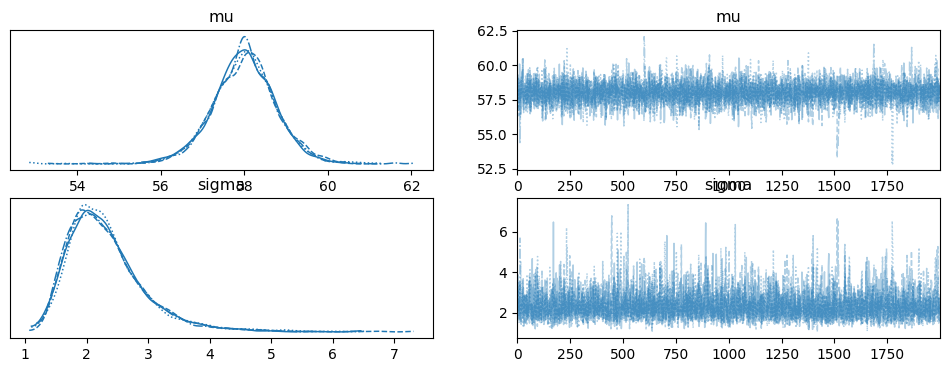

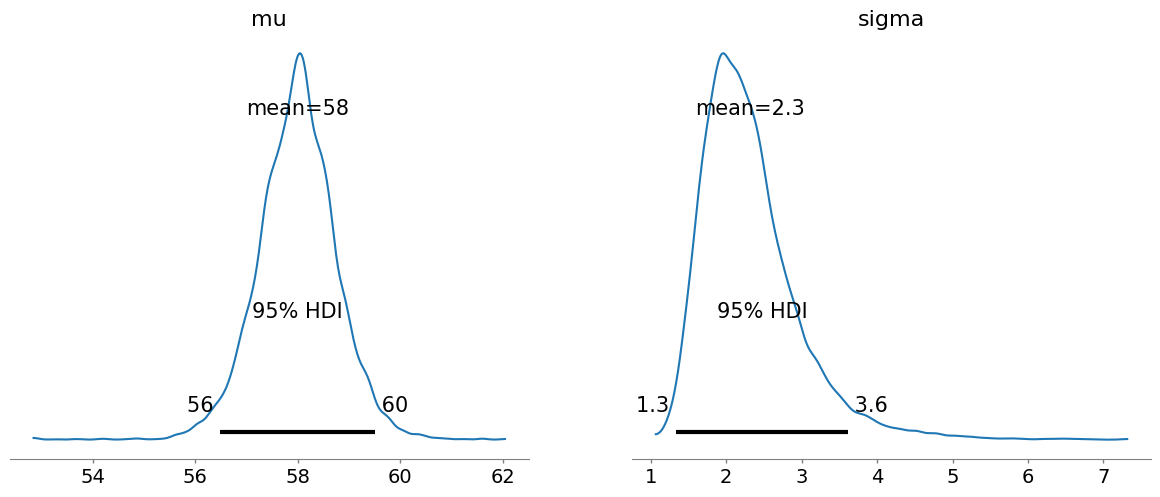

In [ ]:
# b)

with noise_model:
    idata = pm.sample(draws=2000, tune=2000, chains=4, random_seed=42)

print(az.summary(idata, var_names=["mu", "sigma"], hdi_prob=0.95))

az.plot_trace(idata, var_names=["mu", "sigma"])
az.plot_posterior(idata, var_names=["mu", "sigma"], hdi_prob=0.95)

hdi = az.hdi(idata, hdi_prob=0.95)
print("HDI 95% mu:   ", hdi["mu"].values)
print("HDI 95% sigma:", hdi["sigma"].values)